# Notebook 02 — Level of Traffic Stress classification (Furth-inspired v2.2)

Reads `edges_with_variables.gpkg` from **Notebook 01** (which also supplies `grade`/`grade_abs`), assigns
each directed edge a **Level of Traffic Stress** 1–4 using criteria **inspired by Furth v2.2 (May 2022)**,
validates, maps, and exports:

- `network_lts.gpkg` — edges + LTS, for QGIS;
- `network_lts_grade.graphml` — the routing graph for Notebook 04, carrying `lts`, `facility_type`,
  `speed_kmh/mph`, `adt`, **and** `grade`/`grade_abs`.

The classification engine (Tables 1–3 + Note 4) is a faithful transcription of Furth v2.2. Around it the
thesis makes a small number of **deliberate departures** — the method is *Furth-inspired*, not strictly Furth.


## Where this departs from Furth v2.2 (and why)

| # | Departure | Rationale | Scope in the final run |
|---|-----------|-----------|------------------------|
| D1 | Separated cycle tracks are assigned LTS 1 directly, skipping Furth's width test | A physically separated path is the safest facility in the network | 51% of LTS 1 edges (9,772 of 19,182) |
| D2 | Furth-native speed bands are used, with the mph column edges converted to km/h | Keeps the published thresholds exact while reporting in km/h for an Australian context | all speed-banded edges |
| D3 | Traffic volume is class-inferred where direct counts are unavailable | Furth's ADT enters only through coarse bands, so moderate ADT error rarely changes the band | direct counts on 3% of motor edges; 67% of mixed-traffic edges hold under ±50% ADT |
| D4 | Narrow residential laneways may take a service-level ADT where width and class indicate very low traffic | Keeps Furth's default volumes from over-rating genuinely quiet laneways | triggered on 0 edges this run; kept so it stays auditable |
| D5 | On a two-way street, the two directions share the higher (worst-side) LTS | Undirected routing needs one stress value per physical link | raised 213 directed edges to the worst-side LTS |

Furth Note 2 (minimum lane width / reach → mixed traffic) is applied exactly as published, so it sits
inside the engine rather than among these departures.


## The Furth decision tree (what the engine does)

```mermaid
flowchart TD
    E[edge] --> F{facility_type?}
    F -->|excluded| X[LTS 0 — off-network]
    F -->|track| T[LTS 1 — DEPARTURE D1: auto, no width test]
    F -->|mixed| M[Table 1: lane_category x ADT x speed]
    F -->|lane_no_park| L2[Table 2: lanes/dir x width x speed]
    F -->|lane_with_park| L3[Table 3: lane_category x reach x speed]
    L2 --> N4{Note 4: mixed-traffic LTS lower?}
    L3 --> N4
    N4 -->|yes| USEMIX[use the mixed-traffic LTS]
    N4 -->|no| USELANE[keep the bike-lane LTS]
```

**Note 4** (Furth): a painted lane that scores *worse* than simply riding in traffic is not credited — the
edge takes the lower (mixed-traffic) stress. Implemented for both lane tables.


# A — Setup and load


## A.1 Environment and configuration

Imports, project folders, and the global speed-banding flag. `USE_KMH_BANDS` is the only sensitivity
toggle here: `False` uses Furth's literal mph column edges (the final run); `True` uses km/h-rounded
edges for a boundary-rounding check.


In [2]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import Normalize
import osmnx as ox

# Project folder layout (created if missing).
PROJECT_ROOT   = Path(os.getcwd())
DATA_RAW       = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
FIGURES        = PROJECT_ROOT / "figures"
REPORTS        = PROJECT_ROOT / "reports"
for p in (DATA_PROCESSED, FIGURES, REPORTS): p.mkdir(parents=True, exist_ok=True)

KMH_TO_MPH = 0.621371

# ── Speed banding (DEPARTURE D2) ──
# Final run keeps km/h but reads Furth's literal mph column edges. Set USE_KMH_BANDS=True only for the
# boundary-rounding sensitivity (Furth's mph edges x1.609344, rounded to the nearest 0.5 km/h).
USE_KMH_BANDS = False

print(f"Project root : {PROJECT_ROOT}")
print(f"Speed banding: {'km/h-rounded (sensitivity)' if USE_KMH_BANDS else 'Furth-native mph'}")


Project root : c:\Users\aylex\OneDrive - The University of Sydney (Students)\Thesis A\Python Code\Phase 1 + 2
Speed banding: Furth-native mph


## A.2 Load and validate the processed network

Load `edges_with_variables.gpkg`, run a coverage guard (refuse a network that falls short of the cordon),
confirm every required Notebook 01 attribute is present, and derive the mph speed column and the
ADT-measured share.


In [3]:
# Load the Notebook 01 hand-off (one row per directed edge, with every Furth input variable).
EDGES_PATH = DATA_PROCESSED / "edges_with_variables.gpkg"
edges = gpd.read_file(EDGES_PATH)
print(f"Loaded {len(edges):,} edges from {EDGES_PATH.name}")

# Coverage guard: refuse a short network built by an un-fixed Notebook 01.
_cf = DATA_RAW / "study_area_cordon.gpkg"
try:
    _cp = gpd.read_file(_cf, layer="study_area_cordon").to_crs("EPSG:28356").union_all()
except Exception:
    _cp = gpd.read_file(_cf).to_crs("EPSG:28356").union_all()
_eb = edges.to_crs("EPSG:28356").total_bounds
_cb = _cp.bounds
_short = {s: round(g) for s, g in
          [("west", _eb[0]-_cb[0]), ("south", _eb[1]-_cb[1]),
           ("east", _cb[2]-_eb[2]), ("north", _cb[3]-_cb[3])] if g > 250}
assert not _short, (f"NB02: input edges fall short of the cordon by (m): {_short}. "
                    f"Re-run NB01 with the layer fix before grading.")
print("  Coverage guard OK — edges span the study-area cordon")

# Every Furth input column must be present (Notebook 01 produces them all).
REQUIRED = {"facility_type","speed_kmh","speed_source","lane_category","lanes_per_dir",
            "bike_lane_width_ft","bike_lane_reach_ft","adt","adt_source"}
missing = REQUIRED - set(edges.columns)
if missing:
    raise RuntimeError(f"Missing required NB01 columns: {sorted(missing)}. Re-run NB01.")
# Grade is optional-but-expected; fall back to 0 if Notebook 01 ran without a DEM.
if "grade_abs" not in edges.columns:
    print("  ! No grade from NB01 — set to 0. Re-run NB01 A6 with a DEM.")
    edges["grade"] = 0.0; edges["grade_abs"] = 0.0
print("  All required columns present.")

# mph view of the speed, and the share of motor edges with a directly measured ADT.
edges["speed_mph"] = edges["speed_kmh"].astype(float) * KMH_TO_MPH
speed_available  = (edges["speed_source"] == "gps_p85").any()
_meas  = edges["adt_source"].isin({"on_link","nearby_same_type"})
_motor = ~edges["adt_source"].isin({"no_motor_traffic"})
adt_measured_pct = 100 * _meas.sum() / max(int(_motor.sum()), 1)
print(f"  GPS speed available: {speed_available} | "
      f"ADT measured on {adt_measured_pct:.0f}% of motor edges (see D3 diagnostic)")


Loaded 50,560 edges from edges_with_variables.gpkg
  Coverage guard OK — edges span the study-area cordon
  All required columns present.
  GPS speed available: True | ADT measured on 3% of motor edges (see D3 diagnostic)


# B — Furth v2.2 lookup tables and the LTS classifier functions

The Furth imperial speed-band edges (Tables 1–3), their km/h equivalents, the minimum-width fallback
(Note 2), and the three per-facility evaluators (`lts_mixed`, `lts_lane_nopark`, `lts_lane_park`).


In [4]:
# Speed column edges (mph) per table. km/h mode uses the same edges x1.609344 (nearest 0.5).
_EDGES_MPH = {
    "T1": [23.5, 28.5, 33.5, 38.5, 43.5, 48.5],
    "T2": [28.5, 33.5, 38.5, 43.5, 48.5],
    "T3": [28.5, 33.5, 38.5],
}
# Convert mph boundaries into rounded metric speed bins for optional sensitivity checks
_EDGES_KMH = {k: [round(round(m*1.609344*2)/2, 1) for m in v] for k, v in _EDGES_MPH.items()}

def _speed_col(speed_kmh, table):
    """Determine the appropriate speed-bin column index for a given edge speed and Furth table."""
    edges_mph, edges_kmh = _EDGES_MPH[table], _EDGES_KMH[table]
    if USE_KMH_BANDS:
        for i, b in enumerate(edges_kmh):
            if speed_kmh < b: return i
        return len(edges_kmh)
    smph = speed_kmh * KMH_TO_MPH
    for i, b in enumerate(edges_mph):
        if smph < b: return i
    return len(edges_mph)

# ── Table 1 — mixed traffic: lane_category -> list of (adt_max, [lts per col]) ──
T1 = {
    "unlaned_2way":         [(750,[1,1,2,2,3,3,3]),(1500,[1,1,2,3,3,3,3]),(3000,[2,2,2,3,3,4,4]),(np.inf,[2,2,3,3,4,4,4])],
    # Furth v2.2: "Narrow one-way, 1-lane" -> 0-600 / 601-1000 / 1001+
    "narrow_1way":          [(600,[1,1,2,2,3,3,3]),(1000,[2,2,2,3,3,4,4]),(np.inf,[2,3,3,3,4,4,4])],
    # Furth v2.2: "2-way with 1 lane per direction and centerline, or wide 1-way, 1-lane" -> 0-1000 / 1001-1500 / 1501+
    "wide_1way_or_centre": [(1000,[1,1,2,2,3,3,3]),(1500,[2,2,2,3,3,4,4]),(np.inf,[2,3,3,3,4,4,4])],
    "2_lanes_per_dir":      [(8000,[3,3,3,3,4,4,4]),(np.inf,[3,3,4,4,4,4,4])],
    "3plus_per_dir":        [(np.inf,[3,3,4,4,4,4,4])],
}


# Furth v2.2 Note 2 (both lane tables): lanes narrower than 4 ft (next to a kerb) or a lane
# reach below 12 ft are rated with the mixed-traffic table instead.
FURTH_MIN_WIDTH_RULE = True
MIN_LANE_WIDTH_FT, MIN_REACH_FT = 4.0, 12.0

def lts_mixed(speed_kmh, lane_cat, adt, table=None):
    """Evaluate mixed-traffic road segment Level of Traffic Stress (Table 1)."""
    T1 = table or globals()["T1"]
    if lane_cat not in T1: return 3, f"T1[fallback:{lane_cat}]"
    col = _speed_col(speed_kmh, "T1")
    for ri, (amax, row) in enumerate(T1[lane_cat]):
        if adt <= amax: return int(row[col]), f"T1[{lane_cat},r{ri},c{col}]"
    return int(T1[lane_cat][-1][1][col]), f"T1[{lane_cat},last,c{col}]"

# ── Table 2 — bike lane, NO adjacent parking (6 cols) ──
def lts_lane_nopark(speed_kmh, lpd, width_ft):
    """Evaluate bike lane segment LTS without adjacent parking (Table 2)."""
    col  = _speed_col(speed_kmh, "T2")
    wide = (width_ft >= 6.0) if pd.notna(width_ft) else False   # NB01 default 5 ft = narrow
    if lpd <= 1:  row, tag = ([1,1,2,3,3,3] if wide else [2,2,2,3,3,4]), ("1lane_wide" if wide else "1lane_narrow")
    elif lpd == 2: row, tag = ([2,2,2,3,3,3] if wide else [2,2,2,3,4,4]), ("2lane_wide" if wide else "2lane_narrow")
    else:         row, tag = [3,3,3,4,4,4], "3plus_lane"
    return int(row[col]), f"T2[{tag},c{col}]"

# ── Table 3 — bike lane WITH adjacent parking (4 cols) ──
def lts_lane_park(speed_kmh, lane_cat, reach_ft):
    """Evaluate bike lane segment LTS with adjacent parking (Table 3)."""
    col  = _speed_col(speed_kmh, "T3")
    wide = (reach_ft >= 15.0) if pd.notna(reach_ft) else False  # default narrow
    if lane_cat in {"unlaned_2way","narrow_1way","wide_1way_or_centre"}:
        row, tag = ([1,2,2,3] if wide else [2,2,3,3]), ("1lane_wide_reach" if wide else "1lane_narrow_reach")
    elif lane_cat == "2_lanes_per_dir":
        row, tag = ([2,3,3,3] if wide else [3,3,3,3]), ("2lane_wide_reach" if wide else "2lane_narrow_reach")
    else:
        row, tag = [3,3,3,3], "3plus_lane"
    return int(row[col]), f"T3[{tag},c{col}]"

print("Furth tables loaded. Speed-col edges:")
print(f"  mph  : {_EDGES_MPH}")
print(f"  km/h : {_EDGES_KMH}  (used only when USE_KMH_BANDS=True)")

Furth tables loaded. Speed-col edges:
  mph  : {'T1': [23.5, 28.5, 33.5, 38.5, 43.5, 48.5], 'T2': [28.5, 33.5, 38.5, 43.5, 48.5], 'T3': [28.5, 33.5, 38.5]}
  km/h : {'T1': [38.0, 46.0, 54.0, 62.0, 70.0, 78.0], 'T2': [46.0, 54.0, 62.0, 70.0, 78.0], 'T3': [46.0, 54.0, 62.0]}  (used only when USE_KMH_BANDS=True)


# C — Edge classification and symmetric link aggregation

Classify every edge (including departure D1 for separated tracks and Note 2/Note 4 inside the engine),
then apply the conservative worst-side rule so both directions of a physical link share the higher LTS.


In [5]:
def classify_edge(r, table=None, min_rule=None):
    """Classify one edge into an LTS score (0-4), returning (lts, audit_tag).

    The table/min_rule overrides exist only for the D5 before/after diagnostic; the normal call uses
    the module defaults. Order follows the Furth decision tree: exclusions -> track (D1) ->
    Note 2 width/reach fallback -> Note 4 lane-vs-mixed -> mixed-traffic default.
    """
    min_rule = FURTH_MIN_WIDTH_RULE if min_rule is None else min_rule
    fac   = r["facility_type"]
    spd   = float(r["speed_kmh"])
    lane  = r["lane_category"]
    adt   = float(r["adt"])
    lpd   = int(r["lanes_per_dir"]) if pd.notna(r["lanes_per_dir"]) else 1
    width = r["bike_lane_width_ft"]
    reach = r["bike_lane_reach_ft"]

    # Off-network / non-routable.
    if fac == "excluded": return 0, "excluded"
    # Departure D1: separated tracks take LTS 1 directly (no width test).
    if fac == "track":    return 1, "track(D1:auto)"        # DEPARTURE D1

    # Furth Note 2: a bike lane narrower than the minimum (or with too little reach) is rated as mixed traffic.
    if fac in ("lane_no_park", "lane_with_park") and min_rule:      # Furth Note 2
        if fac == "lane_no_park" and pd.notna(width) and width < MIN_LANE_WIDTH_FT:
            lm, rm = lts_mixed(spd, lane, adt, table); return lm, f"note2_width({rm})"
        if fac == "lane_with_park" and pd.notna(reach) and reach < MIN_REACH_FT:
            lm, rm = lts_mixed(spd, lane, adt, table); return lm, f"note2_reach({rm})"

    # Furth Note 4: a painted lane scoring worse than mixed traffic takes the lower (mixed) stress.
    if fac == "lane_no_park":
        ll, rl = lts_lane_nopark(spd, lpd, width)
        lm, rm = lts_mixed(spd, lane, adt, table)
        return (lm, f"note4({rl}->{rm})") if lm < ll else (ll, rl)   # Note 4
    if fac == "lane_with_park":
        ll, rl = lts_lane_park(spd, lane, reach)
        lm, rm = lts_mixed(spd, lane, adt, table)
        return (lm, f"note4({rl}->{rm})") if lm < ll else (ll, rl)   # Note 4

    # Default: mixed traffic (Table 1).
    return lts_mixed(spd, lane, adt, table)

# Classify every edge, then split the (lts, tag) tuple into two columns.
_res = edges.apply(classify_edge, axis=1)
edges["lts"]      = _res.map(lambda t: t[0]).astype(int)
edges["lts_rule"] = _res.map(lambda t: t[1])
print(f"Classification complete ({'km/h bands' if USE_KMH_BANDS else 'Furth mph'}).")
print(edges["lts"].value_counts().sort_index().to_string())

# ── Symmetric LTS (Departure D5): both directions of a physical link share the worst-side rating ──
# Methodology §4.3.3: LTS is symmetric per physical link (grade stays directional). OSMnx stores a
# two-way road as (u,v,k) and (v,u,k); give both the MAX LTS of the pair so a one-sided bike lane never
# lets one direction look safer than it rides. Excluded edges (LTS 0) stay excluded.
if {"u", "v", "key"}.issubset(edges.columns):
    edges["_link"] = [(min(int(u), int(v)), max(int(u), int(v)), int(k))
                      for u, v, k in zip(edges["u"], edges["v"], edges["key"])]
    _pos    = edges["lts"] > 0                             # routable directions only
    _worst  = edges[_pos].groupby("_link")["lts"].max()      # worst-case stress per physical link
    _mapped = edges["_link"].map(_worst)
    _new    = np.where(_pos & _mapped.notna(), _mapped, edges["lts"]).astype(int)
    _raised = _pos & (_new > edges["lts"].to_numpy())        # directions bumped up to the worst side
    edges.loc[_raised, "lts_rule"] = edges.loc[_raised, "lts_rule"] + "|sym_worstside"
    edges["lts"] = _new
    edges.drop(columns="_link", inplace=True)
    print(f"  symmetric LTS (conservative max per physical link): raised {int(_raised.sum())} directed edge(s)")
    print(edges["lts"].value_counts().sort_index().to_string())   # post-symmetric distribution
else:
    print("  ! no u/v/key columns — cannot symmetrise LTS; check NB01 export")


Classification complete (Furth mph).
lts
0     4051
1    19184
2    16990
3     8903
4     1432
  symmetric LTS (conservative max per physical link): raised 213 directed edge(s)
lts
0     4051
1    19182
2    16839
3     8998
4     1490


# D — LTS distribution and integrity diagnostics

The aggregate LTS distribution, the breakdown by facility type, and an assertion that every separated
track is LTS 1 and every excluded edge is LTS 0.

*Provenance:* the LTS distribution (4,051 / 19,182 / 16,839 / 8,998 / 1,490) and the cyclable-network
length reported in the thesis are produced here and in `reports/lts_classification_report.txt`.


In [6]:
# Define descriptive labels for each Level of Traffic Stress (LTS) tier
LTS_DESC = {0:"excluded",1:"LTS 1 - low stress / separated",2:"LTS 2 - mostly low stress",
            3:"LTS 3 - moderate stress",4:"LTS 4 - high stress"}
print("LTS distribution (all edges):")
# Iterate through each LTS tier to compute absolute counts, percentages, and render an ASCII bar distribution
for l in [0,1,2,3,4]:
    n = int((edges["lts"]==l).sum()); pct = 100*n/len(edges)
    print(f"  {l}  {LTS_DESC[l]:<32}{n:>7,}  ({pct:5.1f}%)  {'#'*int(pct/2)}")

# Print cross-tabulation of edge counts grouped by infrastructure facility type and LTS tier
print("\nLTS by facility_type:")
print(edges.groupby(["facility_type","lts"]).size().unstack(fill_value=0).to_string())

# Sanity check validation: ensure Departure D1 rules (tracks = LTS 1) and exclusions (excluded = LTS 0) hold true
bad_t = ((edges["facility_type"]=="track")    & (edges["lts"]!=1)).sum()
bad_x = ((edges["facility_type"]=="excluded") & (edges["lts"]!=0)).sum()
print(("\n  OK: all tracks LTS1, all excluded LTS0." if not (bad_t or bad_x)
       else f"\n  !! {bad_t} tracks!=1, {bad_x} excluded!=0"))

LTS distribution (all edges):
  0  excluded                          4,051  (  8.0%)  ####
  1  LTS 1 - low stress / separated   19,182  ( 37.9%)  ##################
  2  LTS 2 - mostly low stress        16,839  ( 33.3%)  ################
  3  LTS 3 - moderate stress           8,998  ( 17.8%)  ########
  4  LTS 4 - high stress               1,490  (  2.9%)  #

LTS by facility_type:


lts                0     1      2     3     4
facility_type                                
excluded        4051     0      0     0     0
lane_no_park       0     0     41    15     0
lane_with_park     0     0    394   358    20
mixed              0  9410  16404  8625  1470
track              0  9772      0     0     0

  OK: all tracks LTS1, all excluded LTS0.


## D.1 Departure D1 — share of the low-stress network from separated tracks

Quantifies how much of the LTS-1 network comes from the track auto-assignment (D1) versus the standard
Furth tables.


In [7]:
l1 = edges[edges["lts"]==1]
by_track = (l1["facility_type"]=="track").sum()
by_table = len(l1) - by_track
print(f"  LTS-1 edges total        : {len(l1):,}")
print(f"   - from track rule (D1)  : {by_track:,} ({100*by_track/max(len(l1),1):.1f}%)")
print(f"   - from Furth tables     : {by_table:,} ({100*by_table/max(len(l1),1):.1f}%)")
print(f"  => D1 is responsible for {100*by_track/max(len(l1),1):.0f}% of the low-stress network.")

  LTS-1 edges total        : 19,182
   - from track rule (D1)  : 9,772 (50.9%)
   - from Furth tables     : 9,410 (49.1%)
  => D1 is responsible for 51% of the low-stress network.


## D.2 Departure D4 — laneway downgrade impact

Checks for edges given a service-level ADT by the laneway-downgrade rule and reports their LTS mix
(triggered on 0 edges in the final run).


In [8]:
# Count how many network edges were assigned ADT via the laneway downgrade rule (Departure D2)
n_lane = (edges["adt_source"]=="laneway_downgrade").sum()
if n_lane:
    # Filter dataset for laneway-downgraded edges and report their LTS breakdown
    aff = edges[edges["adt_source"]=="laneway_downgrade"]
    print(f"  Laneway-downgrade edges: {n_lane:,}")
    print(f"  Their LTS mix: {aff['lts'].value_counts().sort_index().to_dict()}")
else:
    print("  No laneway_downgrade edges in this run.")

  No laneway_downgrade edges in this run.


## D.3 Departure D3 — ADT sensitivity on mixed-traffic edges

Perturbs ADT by ±50% and reports the share of mixed-traffic edges whose LTS band is unchanged — the
evidence that class-inferred ADT is acceptable given Furth's coarse bands.


In [9]:
# Filter dataset to isolate mixed-traffic road segments
mix = edges[edges["facility_type"]=="mixed"].copy()

# Helper function to compute pure mixed-traffic LTS score (Table 1 lookup)
def _lts_only(s, lane, a): return lts_mixed(s, lane, a)[0]

# Compute baseline LTS score using standard ADT values
base = mix.apply(lambda r: _lts_only(r["speed_kmh"], r["lane_category"], r["adt"]), axis=1)
# Compute lower bound LTS score under a 50% reduction in ADT
lo   = mix.apply(lambda r: _lts_only(r["speed_kmh"], r["lane_category"], r["adt"]*0.5), axis=1)
# Compute upper bound LTS score under a 50% increase in ADT
hi   = mix.apply(lambda r: _lts_only(r["speed_kmh"], r["lane_category"], r["adt"]*1.5), axis=1)

# Count how many mixed edges experience an LTS score change under $\pm 50\%$ ADT perturbation
changed = ((lo!=base) | (hi!=base)).sum()
print(f"  Mixed-traffic edges            : {len(mix):,}")
print(f"  ADT measured on                : {adt_measured_pct:.0f}% of motor edges")
print(f"  Change LTS under ADT +/-50%    : {changed:,} ({100*changed/max(len(mix),1):.1f}%)")
print(f"  => {100-100*changed/max(len(mix),1):.0f}% of mixed edges are INSENSITIVE to ADT error,")
print( "     which is why class-inferred ADT is acceptable (Furth uses coarse bands).")

  Mixed-traffic edges            : 35,909
  ADT measured on                : 3% of motor edges
  Change LTS under ADT +/-50%    : 11,831 (32.9%)
  => 67% of mixed edges are INSENSITIVE to ADT error,
     which is why class-inferred ADT is acceptable (Furth uses coarse bands).


# E — Figures

Nine figures: the LTS map, length by class, facility→LTS composition, the ADT-sensitivity bar, the
rule-family attribution, and the supporting panels.


## E.1 Plotting palette and save helper

Shared LTS colours/labels and a figure-save helper (`_savefig`).


In [10]:
# Define official hex color codes mapped to each Level of Traffic Stress (LTS) tier for map and chart rendering
LTS_COL = {0:"#424143",1:"#007E3B",2:"#F5D000",3:"#E36820",4:"#E64626"}
# Define short display labels for LTS tiers used in plot legends and figure annotations
LTS_LAB = {0:"Excluded",1:"LTS 1",2:"LTS 2",3:"LTS 3",4:"LTS 4"}

def _savefig(name):
    """Format, export at 150 DPI with tight bounding boxes, and display generated figures."""
    plt.rcParams["font.family"] = "Times New Roman"
    plt.tight_layout()
    plt.savefig(FIGURES/name, dpi=150, bbox_inches="tight")
    plt.show()
    print("  saved", name)

## E.2 Network LTS map

Full-extent map of the network coloured by LTS, with low-stress tiers drawn on top.


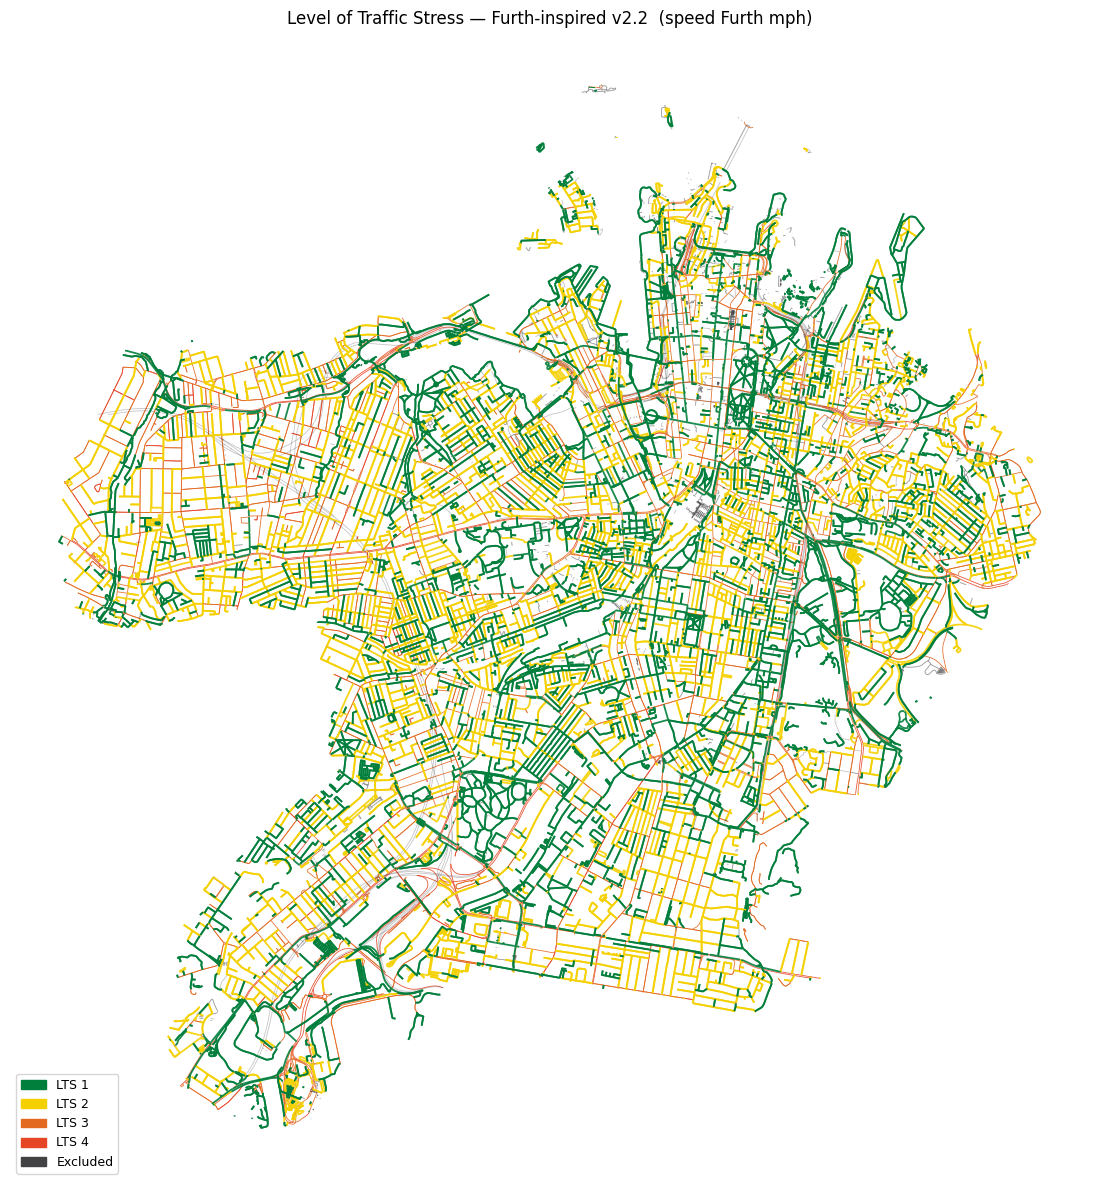

  saved 02_lts_map.png


In [11]:
# Initialise a 12x12 inch matplotlib figure with a clean white background and disabled axis boundaries
fig, ax = plt.subplots(figsize=(12,12)); ax.set_axis_off(); fig.patch.set_facecolor("white")

# Plot network edges iteratively by LTS tier in reverse order (rendering lower stress on top)
for l in [4,3,0,2,1]:
    m = edges["lts"]==l
    if m.any():
        # Plot edges with styled line widths (thicker for low stress LTS 1-2) and alpha opacities (faint for excluded links)
        edges[m].plot(ax=ax, color=LTS_COL[l], linewidth=(1.3 if l in {1,2} else 0.6),
                      alpha=(0.3 if l==0 else 0.9))

# Construct and position the map legend in the lower left corner using predefined color mappings and labels
ax.legend(handles=[mpatches.Patch(color=LTS_COL[l], label=LTS_LAB[l]) for l in [1,2,3,4,0]
                   if (edges["lts"]==l).any()], loc="lower left", fontsize=9)

# Set dynamic figure title reflecting the active speed-banding standard (Furth mph or metric)
band = "km/h" if USE_KMH_BANDS else "Furth mph"
ax.set_title(f"Level of Traffic Stress — Furth-inspired v2.2  (speed {band})", fontsize=12)

# Export and display the generated map figure
_savefig("02_lts_map.png")

## E.3 Network length by LTS tier

Total centreline length (km) per LTS tier across the routable network.


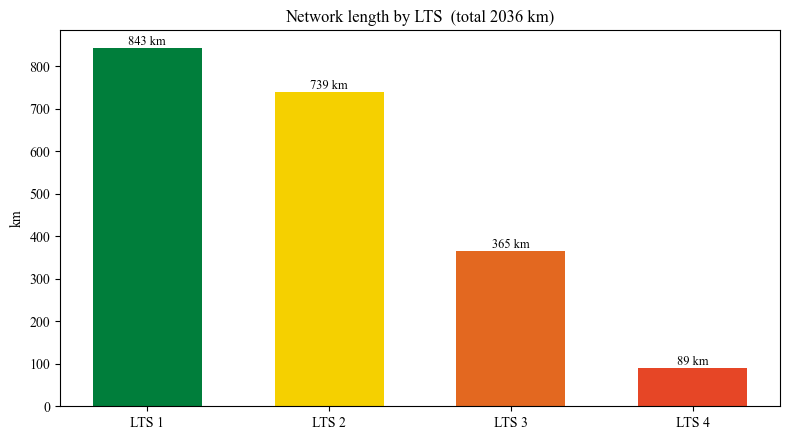

  saved 02_lts_length.png


In [12]:
# Filter dataset to isolate routable network edges (excluding non-routable or excluded links where lts == 0)
cyc = edges[edges["lts"]>0]

# Check if edge length data is available, then compute total network kilometres per LTS tier
if "length" in cyc.columns:
    km = {l: cyc.loc[cyc["lts"]==l,"length"].sum()/1000 for l in [1,2,3,4]}
    
    # Initialize a matplotlib figure with a clean white background
    fig, ax = plt.subplots(figsize=(8,4.5)); fig.patch.set_facecolor("white")
    
    # Create a vertical bar chart mapping each LTS category to its total length in kilometres
    b = ax.bar([LTS_LAB[l] for l in [1,2,3,4]], [km[l] for l in [1,2,3,4]],
               color=[LTS_COL[l] for l in [1,2,3,4]], width=0.6)
               
    # Annotate each bar with its exact kilometre value formatted to zero decimal places
    for bar,l in zip(b,[1,2,3,4]):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height(), f"{km[l]:.0f} km",
                ha="center", va="bottom", fontsize=9)
                
    # Configure axes labels and dynamic title displaying total network length
    ax.set_ylabel("km"); ax.set_title(f"Network length by LTS  (total {sum(km.values()):.0f} km)")
    
    # Export and display the generated chart figure
    _savefig("02_lts_length.png")

## E.4 Facility type → LTS composition

Stacked horizontal bars of edge counts by facility type and LTS.


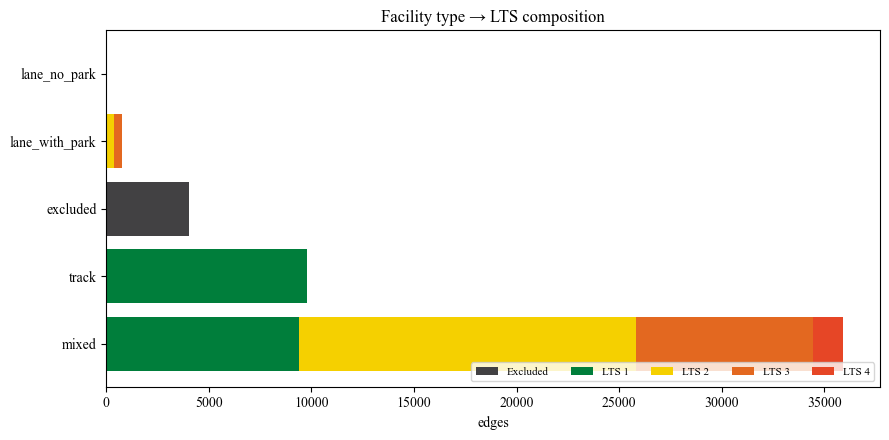

  saved 02_facility_lts.png


In [13]:
# Group network edges by facility type and LTS tier, creating a cross-tabulated contingency matrix
ct = edges.groupby(["facility_type","lts"]).size().unstack(fill_value=0)
# Sort facility types by total edge count in descending order for clearer visual hierarchy
ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index]

# Initialize a matplotlib figure with a clean white background
fig, ax = plt.subplots(figsize=(9,4.5)); fig.patch.set_facecolor("white")
# Initialize baseline tracker for stacked horizontal bar placement
bottom = np.zeros(len(ct))

# Iterate through each LTS tier to plot stacked horizontal bars with standard color coding
for l in [0,1,2,3,4]:
    if l in ct.columns:
        ax.barh(ct.index, ct[l], left=bottom, color=LTS_COL[l], label=LTS_LAB[l])
        bottom += ct[l].values

# Configure axis labels, horizontal legend positioning, and figure title
ax.set_xlabel("edges"); ax.legend(ncol=5, fontsize=8, loc="lower right")
ax.set_title("Facility type → LTS composition")

# Export and display the generated chart figure
_savefig("02_facility_lts.png")

## E.5 ADT sensitivity (Departure D3)

Bar chart of the insensitive vs sensitive mixed-traffic share under ±50% ADT.


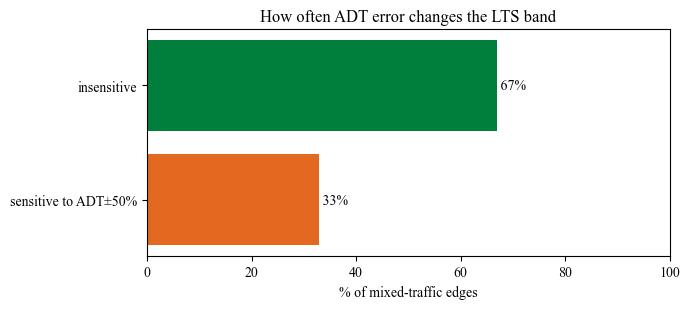

  saved 02_adt_sensitivity.png


In [14]:
# Initialize a compact 7x3.2 inch matplotlib figure with a white background
fig, ax = plt.subplots(figsize=(7,3.2)); fig.patch.set_facecolor("white")

# Calculate percentage of mixed-traffic edges insensitive to a +/-50% ADT change
ins = 100 - 100*changed/max(len(mix),1)

# Create a horizontal bar chart comparing sensitive vs. insensitive mixed-traffic edge proportions
ax.barh(["sensitive to ADT±50%","insensitive"], [100-ins, ins],
        color=["#E36820","#007E3B"])

# Annotate each horizontal bar with its exact percentage value aligned centrally on the right
for i,v in enumerate([100-ins, ins]): ax.text(v, i, f" {v:.0f}%", va="center")

# Configure axis limits (0-100%), axis labels, and chart title
ax.set_xlim(0,100); ax.set_xlabel("% of mixed-traffic edges")
ax.set_title("How often ADT error changes the LTS band")

# Export and display the generated sensitivity chart figure
_savefig("02_adt_sensitivity.png")

## E.6 Rule-family attribution

Which rule family (track, excluded, Note 4, or Table 1/2/3) assigned each edge's LTS.


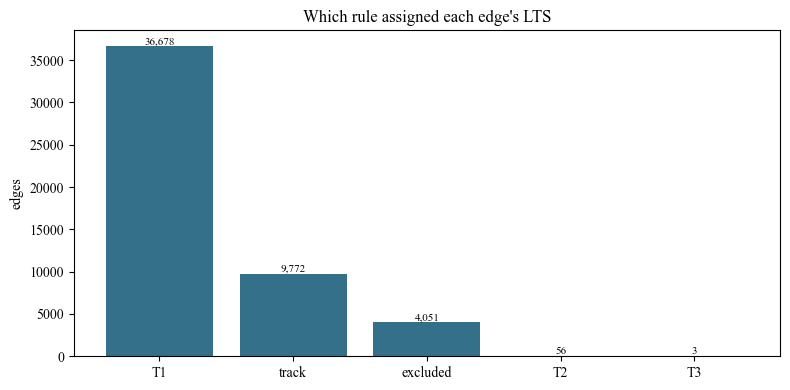

  saved 02_rule_family.png


In [15]:
# Extract the primary classification rule prefix from the audit trail column and fill unparsed entries with "T1"
fam = edges["lts_rule"].str.extract(r"^(track|excluded|note4|T1|T2|T3)")[0].fillna("T1")

# Initialize a matplotlib figure with a white background
fig, ax = plt.subplots(figsize=(8,4)); fig.patch.set_facecolor("white")

# Calculate value counts for each rule family
vc = fam.value_counts()

# Create a vertical bar chart displaying edge counts per rule family
ax.bar(vc.index, vc.values, color="#34708a")

# Annotate each bar with its exact edge count formatted with comma separators
for i,(k,v) in enumerate(vc.items()): ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)

# Configure axis labels and chart title
ax.set_ylabel("edges"); ax.set_title("Which rule assigned each edge's LTS")

# Export and display the generated rule attribution chart figure
_savefig("02_rule_family.png")

# F — Diagnostics


## Real-world corridor spot checks

Validates the classifier against known conditions on benchmark Sydney corridors (Kent St, Parramatta Rd,
etc.) by comparing the modal LTS to the expected rating.


In [16]:
# Define benchmark spot-check corridors with expected LTS ratings and qualitative descriptions
SPOT = [
    ("Kent Street",1,"separated cycleway"),("Wilson Street",1,"highway=cycleway"),
    ("Parramatta Road",4,"primary, no facility, high ADT"),("Harris Street",3,"tertiary, no facility"),
    ("Crown Street",2,"tertiary w/ bike lane"),("Broadway",3,"4-lane arterial, congested p85"),
    ("Elizabeth Street",3,"multilane CBD, congested p85"),
]

def _nmatch(x,t):
    """Safely match search strings across string, list, or array-like edge name attributes."""
    if isinstance(x,(list,tuple,np.ndarray)): return any(t in str(v).lower() for v in x if v is not None)
    try:
        if pd.isna(x): return False
    except (TypeError,ValueError): pass
    return t in str(x).lower()

if "name" in edges.columns:
    p=r=mi=0
    for road,exp,why in SPOT:
        # Filter network edges matching the benchmark road name
        sub = edges[edges["name"].apply(lambda x,t=road.lower(): _nmatch(x,t))]
        if not len(sub): print(f"  ?  NOT FOUND  {road:<18} ({why})"); mi+=1; continue
        # Determine the modal (most frequent) LTS score for the corridor segment
        modal = int(sub["lts"].mode().iloc[0])
        tag = "PASS " if modal==exp else f"got{modal} exp{exp}"
        print(f"  {'OK ' if modal==exp else 'XX '} {tag:<10}{road:<18} dist={sub['lts'].value_counts().sort_index().to_dict()}")
        p += modal==exp; r += modal!=exp
    print(f"\n  Spot checks: {p} pass | {r} review | {mi} missing")

  OK  PASS      Kent Street        dist={1: 55, 2: 14, 3: 12}
  OK  PASS      Wilson Street      dist={1: 66, 2: 6}
  OK  PASS      Parramatta Road    dist={1: 5, 3: 36, 4: 93}
  OK  PASS      Harris Street      dist={0: 4, 1: 4, 2: 22, 3: 76}
  XX  got3 exp2 Crown Street       dist={1: 3, 2: 60, 3: 91, 4: 7}
  OK  PASS      Broadway           dist={1: 5, 3: 33, 4: 7}
  OK  PASS      Elizabeth Street   dist={1: 13, 2: 65, 3: 169, 4: 4}

  Spot checks: 6 pass | 1 review | 0 missing


# G — Export for QGIS and routing (Notebook 04)


## G.1 Export the classified network to GeoPackage

Keep the core attributes, sanitise list-valued columns, and write `network_lts.gpkg` for QGIS.


In [17]:
# Define the prioritized list of attributes and geometric columns to retain for export
keep = ["geometry","length","name","highway","hw","speed_kmh","speed_mph","speed_source",
        "lanes_total","lanes_per_dir","is_oneway","has_centreline","lane_category","facility_type",
        "bike_lane_width_ft","bike_lane_reach_ft","parking","adt","adt_source",
        "grade","grade_abs","lts","lts_rule"]

# Prepend network topology keys and node identifiers if present in the dataset
for c in ["u","v","key","osmid"]:
    if c in edges.columns: keep.insert(0,c)
    
# Filter keep list to include only columns actively present in the edges GeoDataFrame
keep = [c for c in keep if c in edges.columns]
exp = edges[keep].copy()

# Sanitize object columns by converting any list-type entries to strings for OGC GeoPackage format compatibility
for c in exp.columns:
    if c!="geometry" and exp[c].dtype==object:
        exp[c] = exp[c].apply(lambda x: str(x[0]) if isinstance(x,list) else x)

# Define output file path and export the final network GeoDataFrame to a GeoPackage
gpkg = DATA_PROCESSED/"network_lts.gpkg"
exp.to_file(gpkg, driver="GPKG")
print(f"  Saved {gpkg.name}: {len(exp):,} edges, {len(keep)} cols")

  Saved network_lts.gpkg: 50,560 edges, 27 cols


## G.2 Build and export the routing graph (grade in percent)

Load the pinned raw OSM graph, join the classified attributes (converting grade from fraction to
percent, which the routing speed curve expects), drop non-routable (LTS 0) edges, keep the largest
component, and export `network_lts_grade.graphml` for Notebook 04.


In [18]:
# Use the snapshot NB01 recorded to locate the exact raw OSM GraphML file
_pin = DATA_PROCESSED / "osm_snapshot.txt"
if _pin.exists():
    GRAPH_IN = DATA_RAW / _pin.read_text().strip()
else:
    cands = sorted(DATA_RAW.glob("osm_network_*.graphml")) or [DATA_RAW/"osm_network.graphml"]
    GRAPH_IN = cands[-1]
    print(f"  ! osm_snapshot.txt missing - using newest file {GRAPH_IN.name}; re-run NB01 to pin it")
if not GRAPH_IN.exists():
    raise FileNotFoundError(f"No OSM graph in {DATA_RAW}. Run NB01 first.")

# Load the raw OSMnx graph into memory
G = ox.load_graphml(str(GRAPH_IN))
print(f"  Graph: {GRAPH_IN.name} — {len(G.nodes):,} nodes, {len(G.edges):,} edges")

# Validate that topological keys exist for joining table attributes onto graph edges
if not {"u","v","key"}.issubset(edges.columns):
    raise KeyError("edges needs u/v/key to join onto the graph. Reload gpkg without dropping them.")

# Grade is stored as rise/run FRACTION (from NB01 DEM). Parkin's speed curve in
# NB04/NB05 expects grade in PERCENT (kappa_up/down are km/h per percent), so we
# stamp grade onto the routing graph as percent. The gpkg/edges stay in fractions.
GRADE_TO_PCT = 100.0

# Build a fast lookup dictionary mapping edge keys (u, v, key) to classified attributes
lookup = {}
for _, r in edges.iterrows():
    try: key = (str(int(float(r["u"]))), str(int(float(r["v"]))), int(r["key"]))
    except (KeyError,TypeError,ValueError): continue
    lookup[key] = {"lts":int(r["lts"]),"lts_rule":str(r["lts_rule"]),
                   "facility_type":str(r["facility_type"]),"speed_kmh":float(r["speed_kmh"]),
                   "speed_mph":float(r["speed_mph"]),"adt":float(r["adt"]),
                   "grade":float(r.get("grade",0.0)) * GRADE_TO_PCT,
                   "grade_abs":float(r.get("grade_abs",0.0)) * GRADE_TO_PCT}
print(f"  Lookup: {len(lookup):,} classified edges")

# Validate grade percentage scaling statistics
_gp = np.abs([v["grade"] for v in lookup.values()])
if len(_gp):
    print(f"  grade stamped as PERCENT: p95|g| {np.percentile(_gp,95):.1f}%  "
          f"max {_gp.max():.1f}%  (expect ~8% / ~16%, not ~0.08)")

# Attach classified attributes to matching graph edges; assign default fallbacks to unmatched edges
matched = unmatched = 0
for u,v,k,d in G.edges(keys=True, data=True):
    hit = lookup.get((str(u),str(v),int(k)))
    if hit: d.update(hit); matched += 1
    else:   d.update({"lts":0,"lts_rule":"unmatched","facility_type":"unknown",
                     "speed_kmh":float("nan"),"speed_mph":float("nan"),
                     "adt":float("nan"),"grade":0.0,"grade_abs":0.0}); unmatched += 1
print(f"  Matched {matched:,} | unmatched {unmatched:,}")

# Filter out non-routable (lts == 0 or unmatched) edges and isolate the largest connected component
drop = [(u,v,k) for u,v,k,d in G.edges(keys=True,data=True) if int(float(d.get("lts",0)))==0]
G.remove_edges_from(drop)
G.remove_nodes_from([n for n in list(G.nodes) if G.degree(n)==0])
if len(G.edges)==0: raise RuntimeError("0 edges after filtering — check lookup key stringification.")
try:    G = ox.truncate.largest_component(G, strongly=False)
except AttributeError: G = ox.utils_graph.get_largest_component(G, strongly=False)
print(f"  Dropped {len(drop):,} unmatched -> kept {len(G.edges):,} edges, {len(G.nodes):,} nodes")

# Export the final routable network graph with grade percentages for downstream routing (NB04)
out = DATA_PROCESSED/"network_lts_grade.graphml"
ox.save_graphml(G, filepath=str(out))
print(f"  Saved {out.name} (NB04 input)")

  Graph: osm_network_20261023.graphml — 34,769 nodes, 97,818 edges
  Lookup: 50,560 classified edges
  grade stamped as PERCENT: p95|g| 7.9%  max 16.0%  (expect ~8% / ~16%, not ~0.08)
  Matched 50,560 | unmatched 47,258
  Dropped 51,309 unmatched -> kept 45,029 edges, 21,691 nodes
  Saved network_lts_grade.graphml (NB04 input)


## G.3 Bidirectional grade symmetry check

Confirms that opposing directed edges of a two-way link carry opposite-sign grades (summing to ≈ 0).


In [19]:
# Initialize dictionaries and lists to track seen link geometries and directional grade pairs
seen, pairs = {}, []
# Iterate through all directed edges in the network graph with keys and attributes
for u,v,k,d in G.edges(keys=True, data=True):
    g = d.get("grade")
    # Skip edges missing grade values or containing NaN entries
    if g is None or (isinstance(g,float) and np.isnan(g)): continue
    # Construct an undirected physical link ID using sorted node tuples and edge keys
    lid = (min(int(u),int(v)), max(int(u),int(v)), int(k))
    # If the reverse direction has already been logged, record both directional grade values for comparison
    if lid in seen and abs(seen[lid])>0.005: pairs.append((seen[lid], float(g)))
    else: seen[lid] = float(g)

# If bidirectional pairs exist, compute summary statistics on grade symmetry and sign opposition
if pairs:
    d = np.array([a+b for a,b in pairs])
    # Calculate percentage of bidirectional pairs with opposing signs (expecting ~100% for uphill/downhill symmetry)
    opp = np.mean([np.sign(a)!=np.sign(b) for a,b in pairs])*100
    print(f"  Two-way links checked: {len(pairs):,}")
    print(f"  |grade_fwd+grade_rev| mean {np.abs(d).mean():.2g}, max {np.abs(d).max():.2g}")
    print(f"  Opposite-sign: {opp:.1f}% (should be ~100%)")

  Two-way links checked: 18,265
  |grade_fwd+grade_rev| mean 0.0021, max 6.3
  Opposite-sign: 100.0% (should be ~100%)


# H — Classification report


## H.1 LTS classification report

Compiles the method settings, LTS distribution, departure diagnostics, speed/ADT provenance and gradient
statistics into `reports/lts_classification_report.txt` — this notebook's end-of-run key-results printout.


In [20]:
# Extract absolute gradient values as a numpy float array for summary statistics
g = edges["grade_abs"].to_numpy(float)

# Initialize the report lines list with header information, methodological parameters, and configuration flags
rep = ["LTS CLASSIFICATION REPORT","="*55,"",
   "Method: Furth-INSPIRED v2.2 (Tables 1-3 + Notes 2 and 4) with documented departures D1-D5",
   f"Furth Note 2 (min lane width 4 ft / reach 12 ft -> mixed traffic): {'ON' if FURTH_MIN_WIDTH_RULE else 'OFF'}",
   f"Speed bands: {'km/h-rounded sensitivity' if USE_KMH_BANDS else 'Furth-native mph'}",
   f"Edges: {len(edges):,}   GPS speed: {speed_available}   ADT measured: {adt_measured_pct:.0f}% of motor edges",
   "","LTS distribution:"]

# Append counts and percentage shares for each Level of Traffic Stress tier (0 to 4)
for l in [0,1,2,3,4]:
    n=int((edges['lts']==l).sum()); rep.append(f"  {l}  {LTS_DESC[l]:<32}{n:>7,} ({100*n/len(edges):5.1f}%)")

# Append total routable cycling network length in kilometres if geometry length is available
if "length" in edges.columns:
    rep += ["", f"Cycling network length: {edges.loc[edges['lts']>0,'length'].sum()/1000:.1f} km"]

# Calculate diagnostic metrics for Departure D1 (track override) and D4/D3 (ADT sensitivity)
l1n=(edges['lts']==1).sum(); tr=((edges['lts']==1)&(edges['facility_type']=='track')).sum()
rep += ["","Departure diagnostics:",
   f"  D1 track->LTS1 accounts for {100*tr/max(l1n,1):.0f}% of LTS-1 edges",
   f"  D4 mixed edges insensitive to ADT+/-50%: {100-100*changed/max(len(mix),1):.0f}%",
   "","Speed-source breakdown:"]

# Append value counts for each speed data provenance category
for k,v in edges["speed_source"].value_counts().items(): rep.append(f"  {k:<24}{v:>7,}")
rep += ["","ADT-source breakdown:"]

# Append value counts for each ADT volume estimation source category
for k,v in edges["adt_source"].value_counts().items(): rep.append(f"  {k:<24}{v:>7,}")

# Append elevation gradient percentile statistics (p50, p90, max) and output file paths
rep += ["", f"Gradient |grade| p50 {np.percentile(g,50)*100:.2f}% p90 {np.percentile(g,90)*100:.2f}% max {g.max()*100:.2f}%",
   "","Outputs:", f"  {DATA_PROCESSED/'network_lts.gpkg'}", f"  {DATA_PROCESSED/'network_lts_grade.graphml'}"]

# Write the compiled report text to the designated report file path and print to standard output
txt = "\n".join(rep); (REPORTS/"lts_classification_report.txt").write_text(txt)
print(txt)

LTS CLASSIFICATION REPORT

Method: Furth-INSPIRED v2.2 (Tables 1-3 + Notes 2 and 4) with documented departures D1-D5
Furth Note 2 (min lane width 4 ft / reach 12 ft -> mixed traffic): ON
Speed bands: Furth-native mph
Edges: 50,560   GPS speed: True   ADT measured: 3% of motor edges

LTS distribution:
  0  excluded                          4,051 (  8.0%)
  1  LTS 1 - low stress / separated   19,182 ( 37.9%)
  2  LTS 2 - mostly low stress        16,839 ( 33.3%)
  3  LTS 3 - moderate stress           8,998 ( 17.8%)
  4  LTS 4 - high stress               1,490 (  2.9%)

Cycling network length: 2036.4 km

Departure diagnostics:
  D1 track->LTS1 accounts for 51% of LTS-1 edges
  D4 mixed edges insensitive to ADT+/-50%: 67%

Speed-source breakdown:
  gps_p85                  31,565
  tfnsw_signposted         13,355
  nsw_statutory_default     5,227
  osm_maxspeed                413

ADT-source breakdown:
  harvey_scaled            36,819
  no_motor_traffic         10,419
  class_average      